# **MÓDULO 17 - Projeto de Credit Score - Parte 1 - Processamento dos dados**


Essa é a primeira etapa do processo de Credit Score que vocês desenvolverão durante nosso curso.
Nessa primeira etapa vocês irão aplicar os passos aprendidos nos módulos de pré processamento para preparar a base de vocês para o desenvolvimento do modelo.

O termo "credit score" se refere a uma pontuação numérica que representa a credibilidade de um indivíduo em termos de cumprimento de obrigações financeiras, como pagar contas de empréstimos, cartões de crédito, entre outros. Essa pontuação é calculada com base em diversas informações financeiras e de crédito do indivíduo, como histórico de pagamentos, níveis de endividamento, tempo de crédito, tipos de crédito utilizados, entre outros.

O objetivo de um modelo de credit score é prever o risco de um indivíduo se tornar inadimplente com suas obrigações financeiras. Em outras palavras, o modelo avalia a probabilidade de um indivíduo não cumprir com os pagamentos de empréstimos ou outros compromissos financeiros. Essa previsão é fundamental para instituições financeiras, como bancos e credores, na tomada de decisão sobre a concessão de crédito. Um modelo de credit score eficaz pode ajudar essas instituições a avaliar o risco de emprestar dinheiro a um determinado indivíduo e, assim, tomar decisões mais informadas sobre a aprovação ou negação de crédito, bem como sobre os termos e condições desses empréstimos.

**Atenção:** Notem que esse projeto é diferente da base que tenho trabalhado com vocês em aula, apesar de se tratar de uma base bancária durante a aula falamos sobre a variável Churn a ser prevista, nesse caso a previsão seria do valor do Score de Crédito.

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

In [27]:
#Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("CREDIT_SCORE_PROJETO_PARTE1.csv", delimiter=';')

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


Legenda dos dados:

*   **Age** : Idade dos nossos clientes.

*   **Income** : Salário Mensal.

*   **Gender** : Gênero.

*   **Education** : Nível de escolaridade dos clientes.

*   **Marital** : Status Civilmente.

*   **Number of Children** : Quantidade de filhos.

*   **Home** : Tipo de residência, alugada ou própria.

*   **Credit Score** : Nossa variável preditora, o score de crédito dos clientes.


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 130 non-null    float64
 1   Gender              164 non-null    str    
 2   Income              164 non-null    str    
 3   Education           164 non-null    str    
 4   Marital Status      164 non-null    str    
 5   Number of Children  164 non-null    int64  
 6   Home Ownership      164 non-null    str    
 7   Credit Score        164 non-null    str    
dtypes: float64(1), int64(1), str(6)
memory usage: 17.8 KB


In [29]:
df.shape

(164, 8)

In [30]:
df['Income'] = (
    df['Income']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [31]:
print(df['Income'].dtype)
print(df['Income'].head(10))

float64
0     50000.0
1    100000.0
2     75000.0
3    125000.0
4    100000.0
5    150000.0
6     40000.0
7     60000.0
8     80000.0
9    105000.0
Name: Income, dtype: float64


**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [32]:
#Verificando se existem dados faltantes
df.isnull().values.any()
#Porcentagem de valores nulos
(df.isnull().sum() / len(df)) * 100

Age                   20.731707
Gender                 0.000000
Income                 0.000000
Education              0.000000
Marital Status         0.000000
Number of Children     0.000000
Home Ownership         0.000000
Credit Score           0.000000
dtype: float64

In [33]:
# Como a quantidade de valores nulos na idade é de 20%, é uma quantidade grande de elementos para serem excluidos, optei então de substituir
#os valores nulos pela média de idades.
df['Age'] = df['Age'].fillna(df['Age'].mean())

#verificando novamente 
df.isnull().values.any()
#Porcentagem de valores nulos
(df.isnull().sum() / len(df)) * 100

Age                   0.0
Gender                0.0
Income                0.0
Education             0.0
Marital Status        0.0
Number of Children    0.0
Home Ownership        0.0
Credit Score          0.0
dtype: float64

**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [34]:
for coluna in df.select_dtypes(include=['object', 'str']).columns:
    print(f'\nColuna: {coluna}')
    print(df[coluna].value_counts(dropna=False))


Coluna: Gender
Gender
Female    86
Male      78
Name: count, dtype: int64

Coluna: Education
Education
Bachelor's Degree      42
Master's Degree        36
Doctorate              31
High School Diploma    30
Associate's Degree     25
Name: count, dtype: int64

Coluna: Marital Status
Marital Status
Married    87
Single     77
Name: count, dtype: int64

Coluna: Home Ownership
Home Ownership
Owned     111
Rented     53
Name: count, dtype: int64

Coluna: Credit Score
Credit Score
High       113
Average     36
Low         15
Name: count, dtype: int64


In [ ]:
# nao encontrei erros ou formas diferentes de digitação na base.

# Etapa 2: Relize os passos que vimos no módulo 15, de análise.

**A) Realiza a análise univariada, aplique a função describe ao nosso dataframe para verificar os dados das variáveis numéricas, se encontrar a possível presença de outliers analise com gráficos a distribuição dos dados.Traga insights sobre os dados analisados.**

In [35]:
df.describe()

,Age,Income,Number of Children
count,164.000000,164.000000,164.000000
mean,37.507692,83765.243902,0.652439
std,7.561808,32457.306728,0.883346
min,25.000000,25000.000000,0.000000
25%,31.750000,57500.000000,0.000000
50%,37.507692,83750.000000,0.000000
75%,43.000000,105000.000000,1.000000
max,53.000000,162500.000000,3.000000


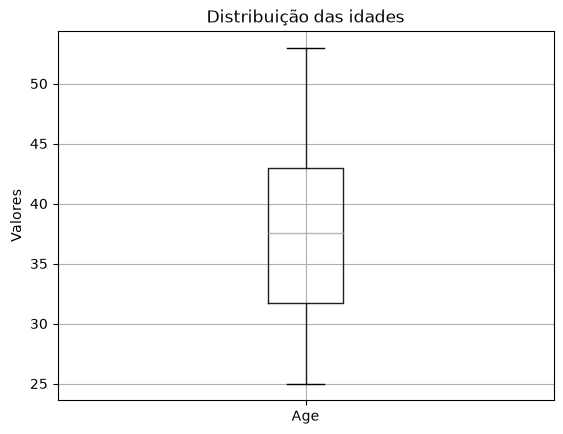

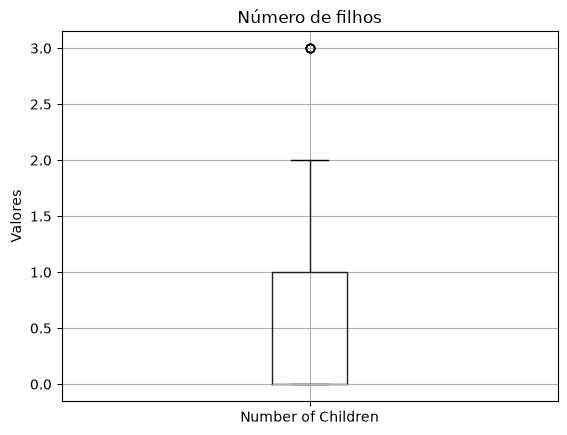

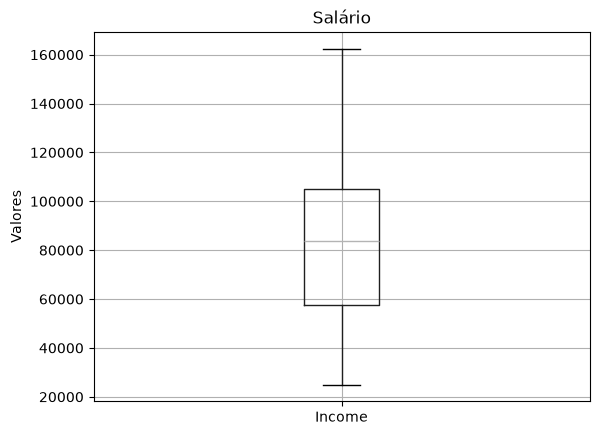

In [37]:
#analisando possiveis outliers
df.boxplot(column='Age')
plt.title('Distribuição das idades')
plt.ylabel('Valores')
plt.show()

df.boxplot(column='Number of Children')
plt.title('Número de filhos')
plt.ylabel('Valores')
plt.show()

df.boxplot(column='Income')
plt.title('Salário')
plt.ylabel('Valores')
plt.show()

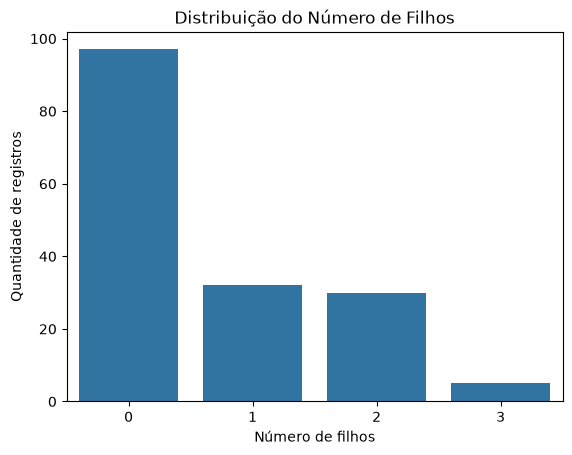

Number of Children
0    97
1    32
2    30
3     5
Name: count, dtype: int64

In [38]:
# existe a presença de outlier na coluna número de filhos, vamos verificar melhor
sns.countplot(data=df, x='Number of Children')

plt.title('Distribuição do Número de Filhos')
plt.xlabel('Número de filhos')
plt.ylabel('Quantidade de registros')
plt.show()

df['Number of Children'].value_counts().sort_index()

**B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

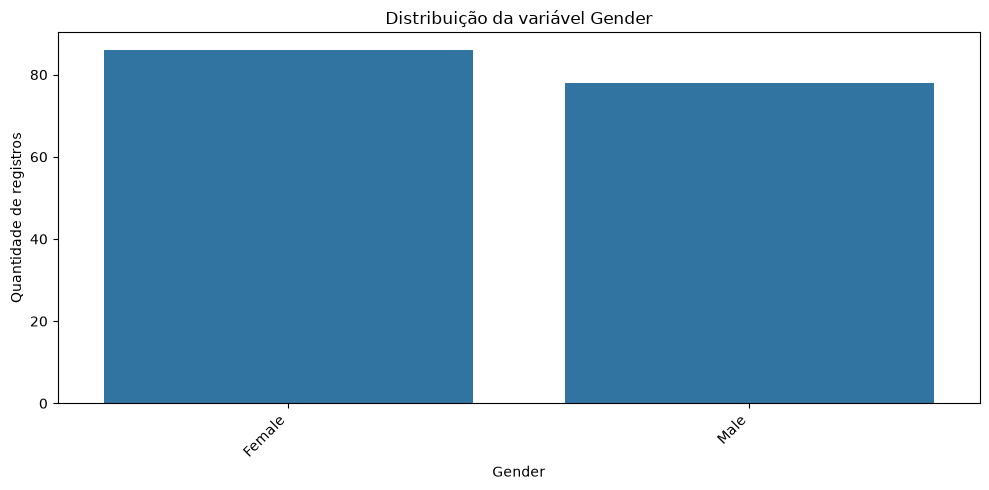

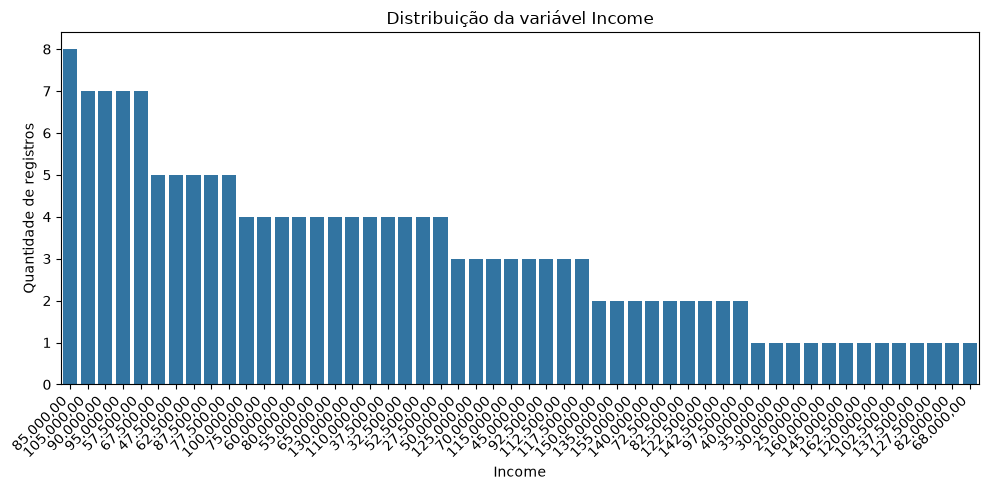

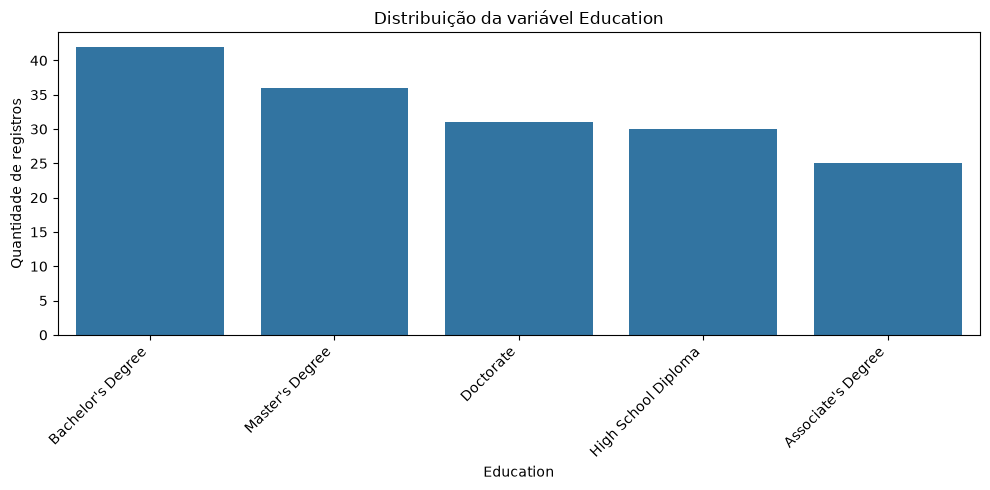

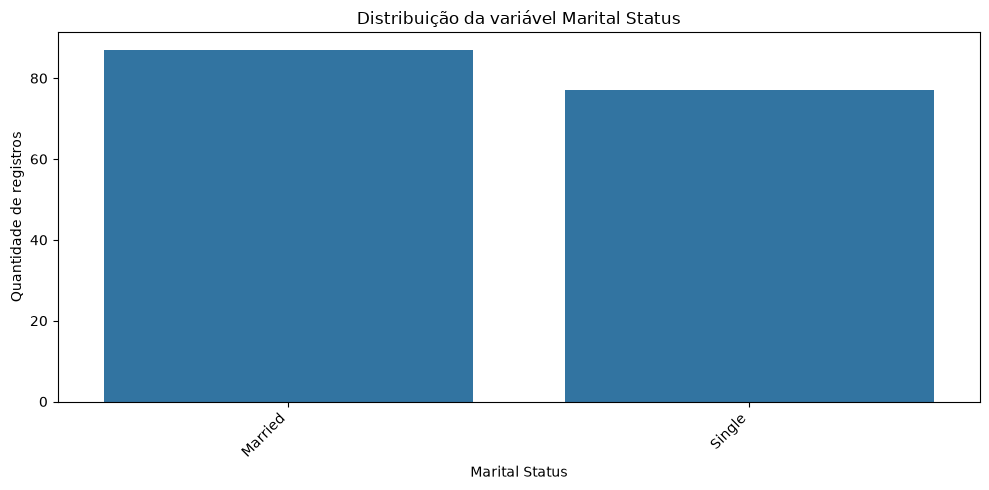

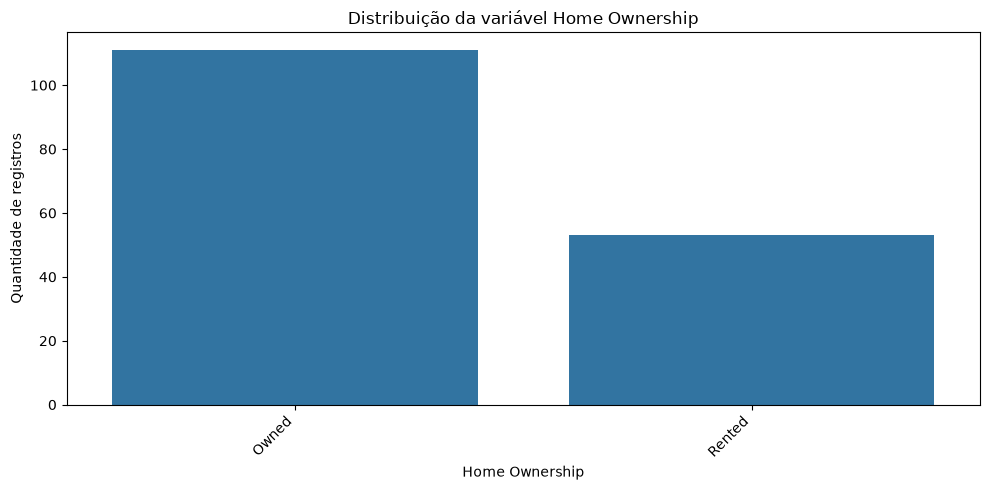

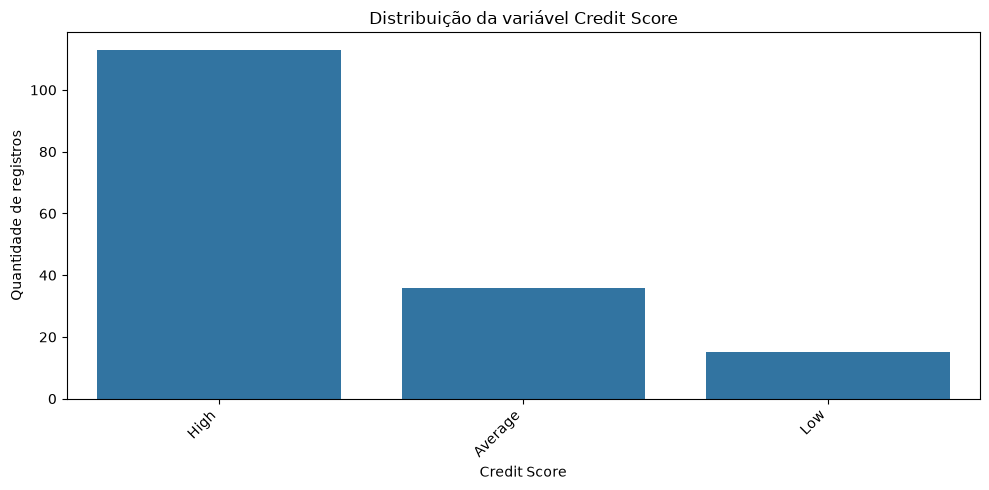

In [20]:
colunas_categoricas = df.select_dtypes(include=['object', 'str']).columns

for coluna in colunas_categoricas:
    plt.figure(figsize=(10, 5))

    ordem = df[coluna].value_counts().index

    sns.countplot(data=df, x=coluna, order=ordem)

    plt.title(f'Distribuição da variável {coluna}')
    plt.xlabel(coluna)
    plt.ylabel('Quantidade de registros')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

**C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.**

In [ ]:
# na coluna quantidade de filhos aparecem 5 cadastros com 3 filhos identificando possibilidade de outlier mas não é um valor que altere nossa análise.

**D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:**



*   Existe relação entre a idade e o status civil?
*   Qual a relação entre o score de crédito e o nível de escolaridade?
*  O salário parece influenciar na idade?
* O salário parece influenciar no Score de Crédito?
* Clientes com casa própria tendem a ter um score mais alto?



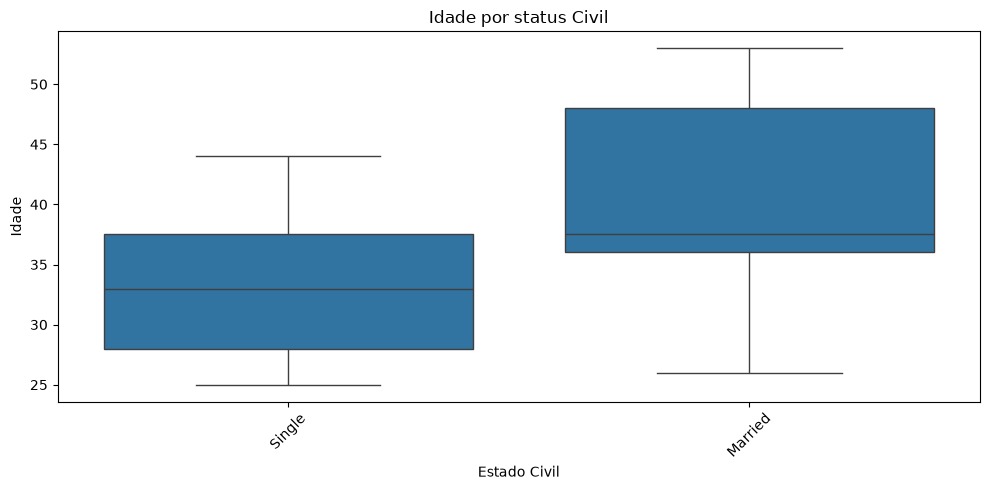

In [43]:
#Existe relação entre a idade e o status civil?
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='Marital Status', y= 'Age')

plt.title('Idade por status Civil')
plt.xlabel('Estado Civil')
plt.ylabel('Idade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Analisando o gráfico, percebemos que pessoas mais jovens apresentam na maioria dos casos um estado civil solteiro e mais velhas casadas.

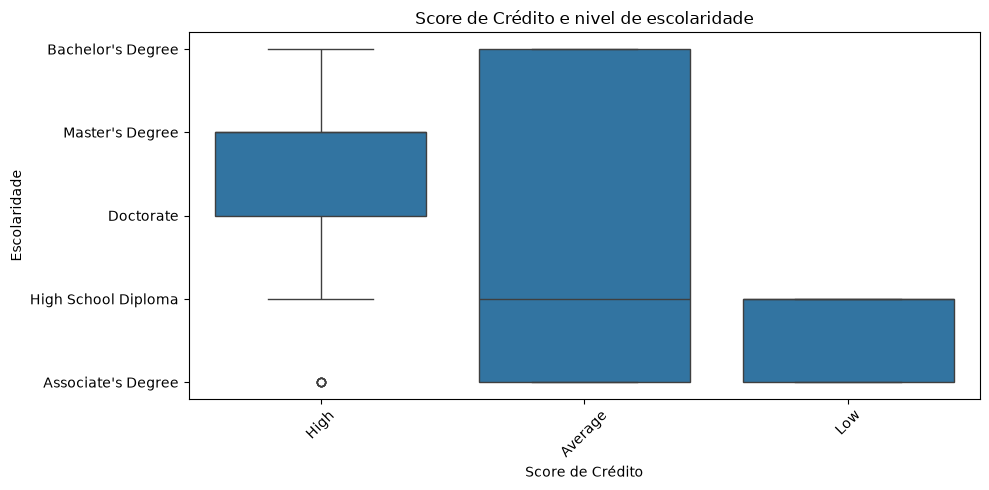

In [45]:
#Qual a relação entre o score de crédito e o nível de escolaridade?
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='Credit Score', y='Education')

plt.title('Score de Crédito e nivel de escolaridade')
plt.xlabel('Score de Crédito')
plt.ylabel('Escolaridade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Nessa parte analisamos que o nível de escolaridade tem uma relação forte com o Score de crédito

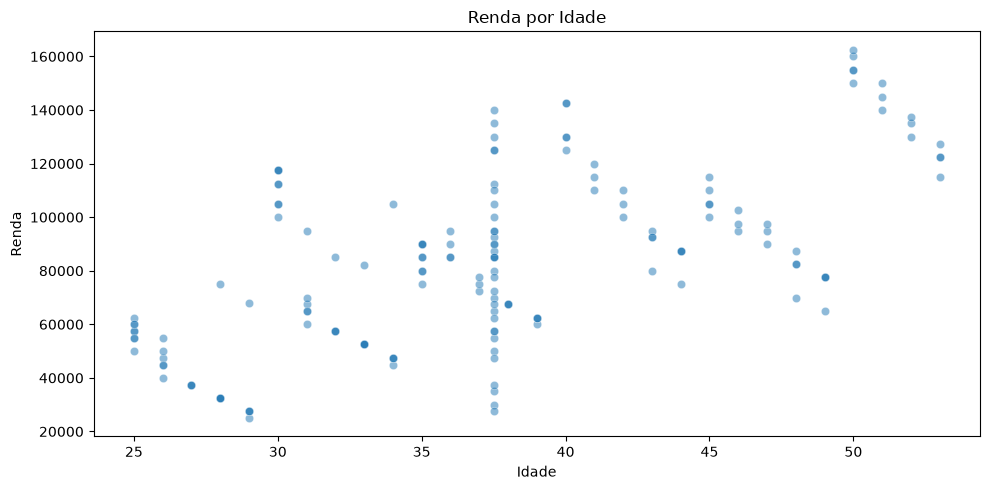

In [46]:
#O salário parece influenciar na idade?
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Age', y='Income', alpha=0.5)

plt.title('Renda por Idade')
plt.xlabel('Idade')
plt.ylabel('Renda')
plt.tight_layout()
plt.show()

In [ ]:
#Percebemos que pessoas mais jovens tendem a ter uma renda menor e vice versa. Percebe-se também que existe uma quantidade distribuidada entre
#todas as rendas em pessoas com a média de idade. Isso também pode estar ocorrendo porque na idade substituimos os valores nulos pela média.

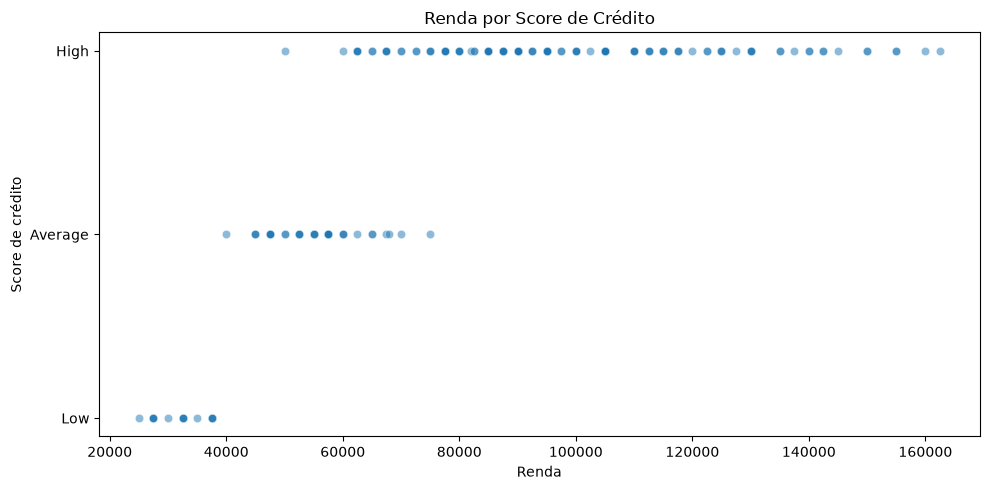

In [47]:
#O salário parece influenciar no Score de Crédito?
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Income', y='Credit Score', alpha=0.5)

plt.title('Renda por Score de Crédito')
plt.xlabel('Renda')
plt.ylabel('Score de crédito')
plt.tight_layout()
plt.show()

In [ ]:
#Sim, o salário incluencia no Score de Crédito, pessoas com salário acima de 60000 apresentam Score medio e alto.

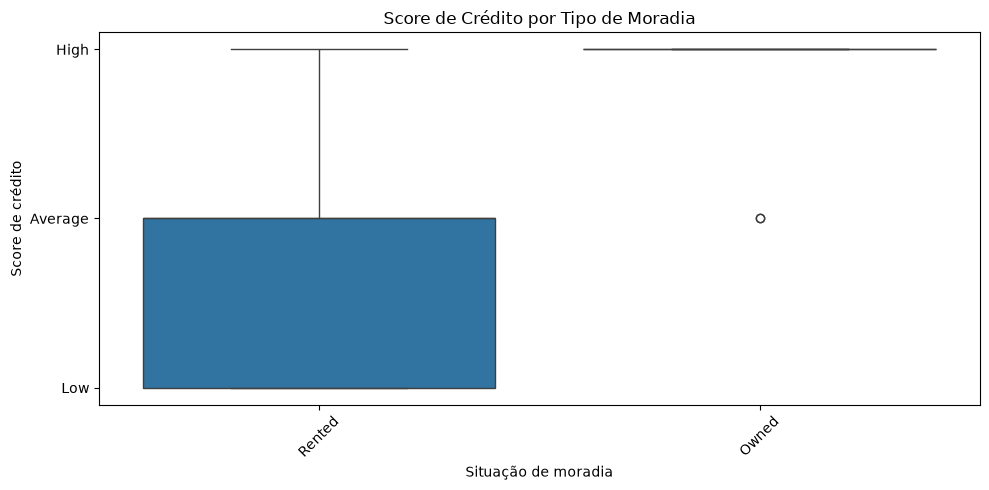

In [48]:
#Clientes com casa própria tendem a ter um score mais alto?
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Home Ownership', y='Credit Score')

plt.title('Score de Crédito por Tipo de Moradia')
plt.xlabel('Situação de moradia')
plt.ylabel('Score de crédito')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Percebemos que pessoas com moradia própria na sua maioria esmagadora apresentam Score de Crédito alto.

**E) Que outras perguntas te parecem fazer sentido explorarmos a resposta para conhecermos mais nossa base de dados e o comportamento dos clientes?**

 Elabore mais 3 perguntas e responda utilizando gráficos + insights.

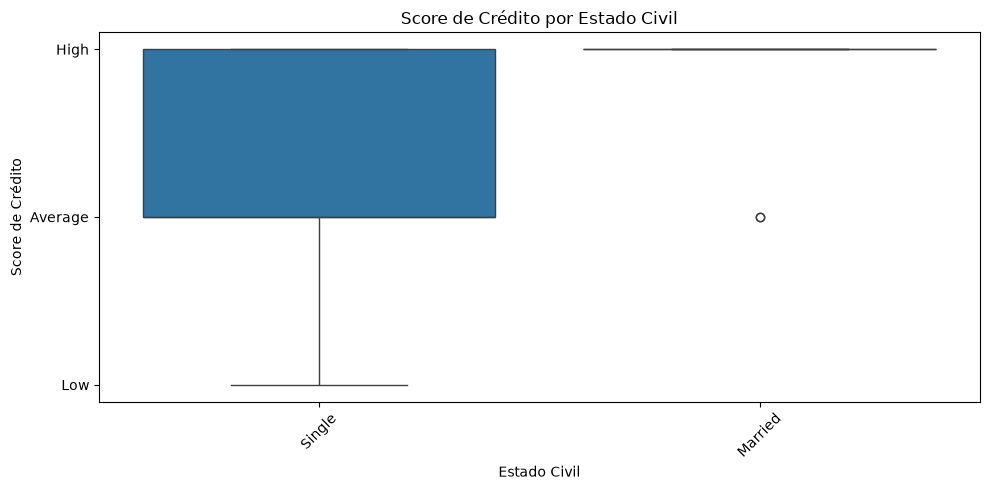

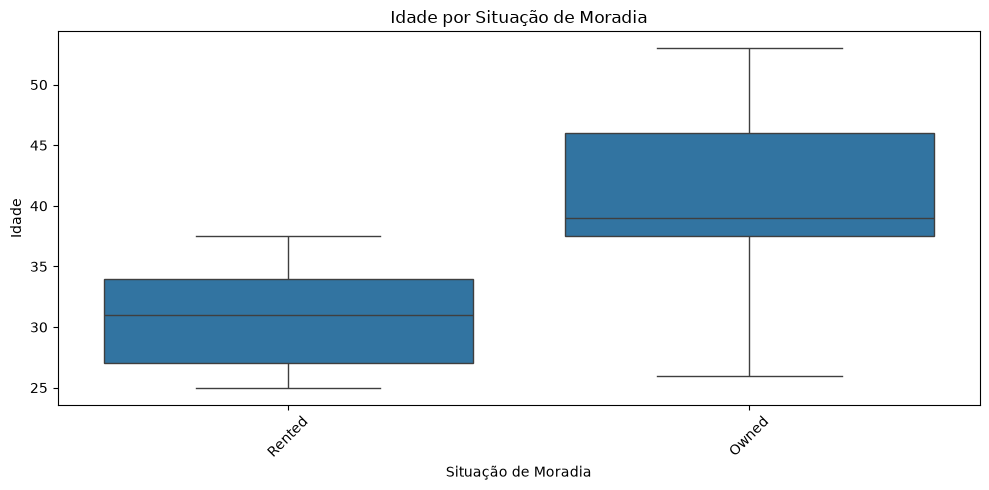

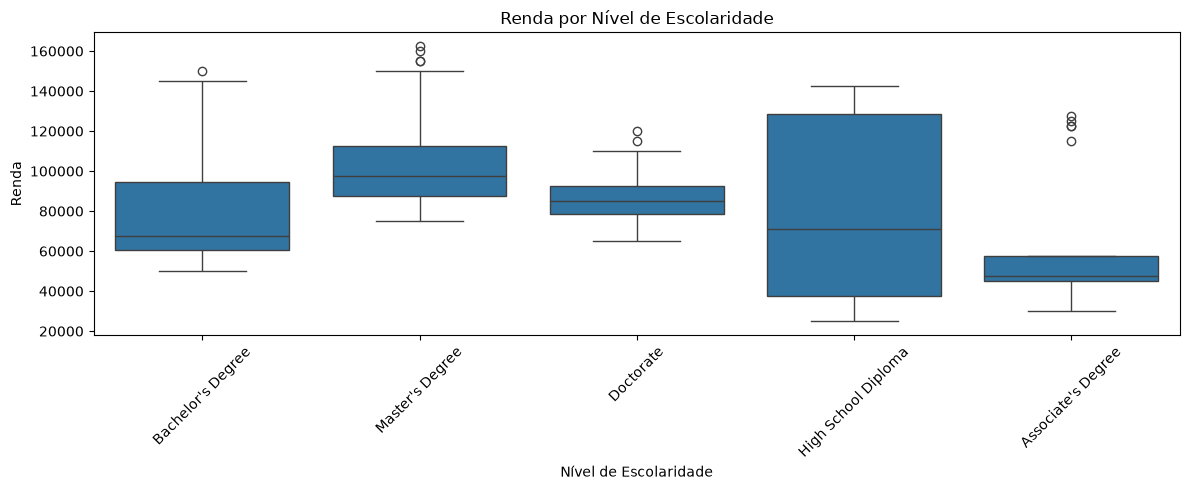

In [49]:
# Estado civil influencia no Score de Crédito?
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Marital Status', y='Credit Score')

plt.title('Score de Crédito por Estado Civil')
plt.xlabel('Estado Civil')
plt.ylabel('Score de Crédito')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Idade e Casa própia estao relacionados?
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Home Ownership', y='Age')

plt.title('Idade por Situação de Moradia')
plt.xlabel('Situação de Moradia')
plt.ylabel('Idade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Nivel de escolaridade influencia na renda?
plt.figure(figsize=(12, 5))

sns.boxplot(data=df, x='Education', y='Income')

plt.title('Renda por Nível de Escolaridade')
plt.xlabel('Nível de Escolaridade')
plt.ylabel('Renda')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
#A análise da base de Credit Score identificou três padrões relevantes.
#O estado civil apresenta associação expressiva com o score de crédito, com maior concentração de scores altos entre os clientes casados.
#A situação de moradia também está associada à idade, uma vez que os proprietários apresentam idade mediana superior à dos clientes que alugam imóveis.
#Por fim, a escolaridade apresenta relação com a renda, mas sem uma progressão uniforme entre todas as categorias.
#Esses resultados ajudam a compreender o perfil dos clientes e podem orientar análises posteriores, 
#mas não permitem estabelecer relações de causalidade.


# Etapa 3: Realize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

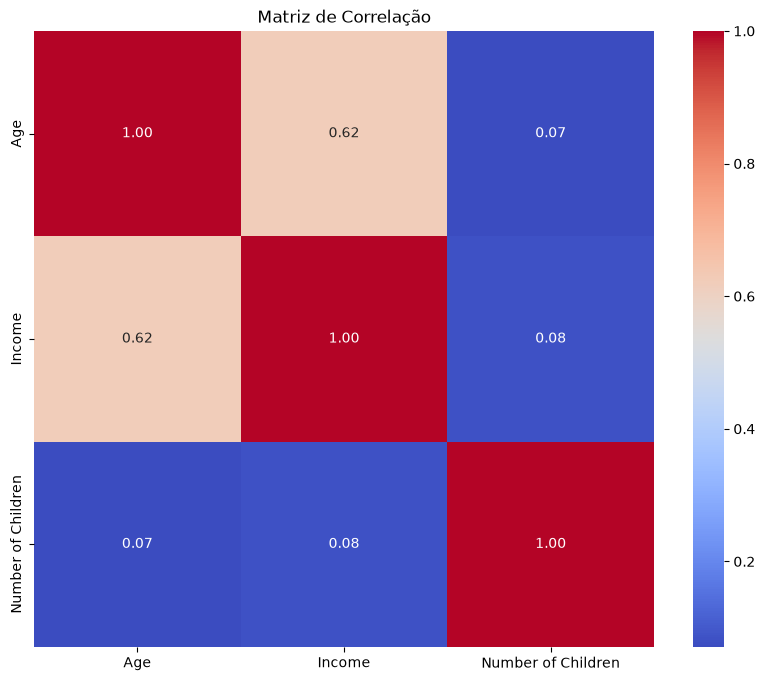

In [50]:
correlation_matrix = df.select_dtypes(include=['number']).corr()

# Plotar o mapa de calor da matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 10})
plt.title('Matriz de Correlação')
plt.show()

**B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.**

In [ ]:
# Idade e Salário tem alta correlação como ja era esperado pelas análises feitas anteriormente.

**C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.**

In [51]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

colunas_categoricas = df.select_dtypes(include=['object','str']).columns

for coluna in colunas_categoricas:
    df[coluna] = le.fit_transform(df[coluna].astype(str))

print(df.head())

    Age  Gender    Income  Education  Marital Status  Number of Children  \
0  25.0       0   50000.0          1               1                   0   
1  30.0       1  100000.0          4               0                   2   
2  35.0       0   75000.0          2               0                   1   
3  40.0       1  125000.0          3               1                   0   
4  45.0       0  100000.0          1               0                   3   

   Home Ownership  Credit Score  
0               1             1  
1               0             1  
2               0             1  
3               0             1  
4               0             1  


**D) Vamos plotar novamente a correlação, agora observando com as variáveis categóricas. Identifique se temos novas variáveis com forte correlação.**

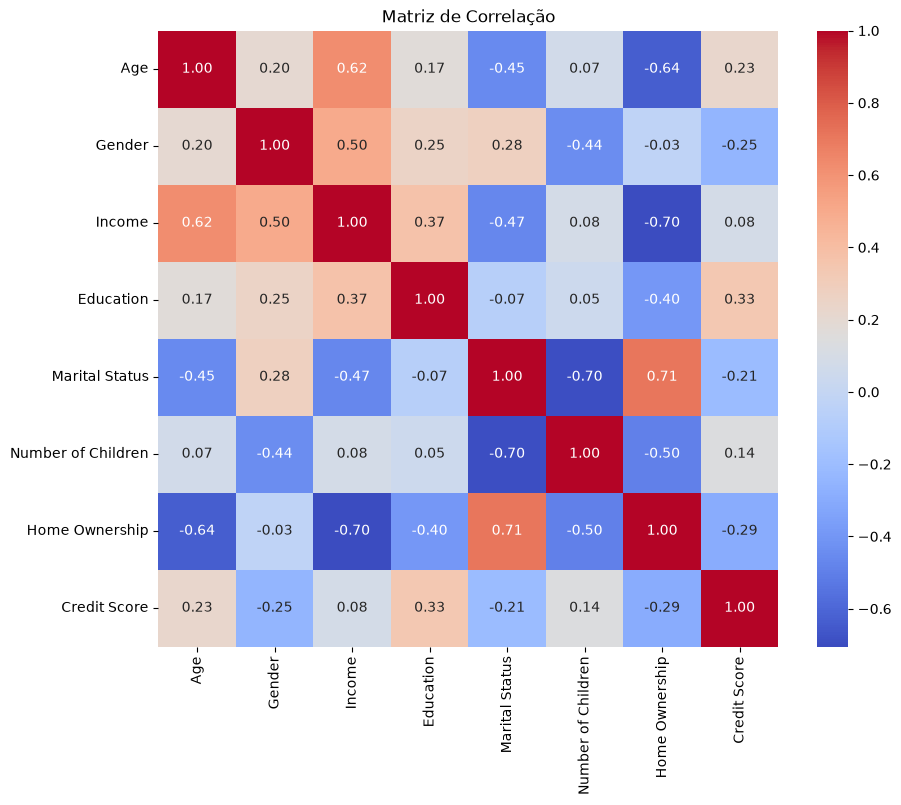

In [52]:
correlation_matrix = df.select_dtypes(include=['number']).corr()

# Plotar o mapa de calor da matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={"size": 10})
plt.title('Matriz de Correlação')
plt.show()

**F) Faça a separação da base em treino e teste e verifique utilizando shape:**

In [53]:
# Separar os dados em features (X) e o alvo (y)
X = df.drop('Credit Score', axis=1)  # Considerando que 'Credit Score' é a coluna a ser predita
y = df['Credit Score']

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
# Separar os dados em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
# O parâmetro 'test_size' determina a proporção dos dados que serão separados para teste (25% neste exemplo)
# O parâmetro 'random_state' é usado para garantir que a divisão seja reproduzível

In [56]:
X_train

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership
141,26.000000,0,45000.0,0,1,0,1
117,29.000000,0,27500.0,3,1,0,1
93,25.000000,0,62500.0,1,1,0,1
133,29.000000,0,68000.0,2,0,2,0
36,31.000000,1,65000.0,1,1,0,1
...,...,...,...,...,...,...,...
71,46.000000,0,97500.0,3,0,1,0
106,32.000000,1,57500.0,0,1,0,1
14,37.507692,0,70000.0,1,0,2,0
92,37.507692,0,85000.0,2,0,1,0


In [57]:
X_test

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership
135,25.000000,0,55000.0,1,1,0,1
115,48.000000,0,87500.0,2,0,1,0
131,26.000000,0,55000.0,1,0,1,0
55,39.000000,0,62500.0,1,0,2,0
95,35.000000,0,90000.0,2,0,1,0
29,25.000000,0,55000.0,1,1,0,1
157,48.000000,0,82500.0,2,0,1,0
51,48.000000,0,82500.0,2,0,1,0
101,36.000000,0,95000.0,4,0,2,0
145,37.507692,0,95000.0,3,0,1,0


In [58]:
y_train

141    0
117    2
93     0
133    0
36     0
      ..
71     1
106    0
14     1
92     1
102    1
Name: Credit Score, Length: 123, dtype: int64

In [59]:
y_test

135    0
115    1
131    0
55     1
95     1
29     0
157    1
51     1
101    1
145    1
19     0
85     2
15     1
66     1
24     2
30     1
132    1
105    2
152    1
16     1
75     1
18     2
12     2
9      1
31     1
155    1
98     1
56     1
134    1
160    0
139    1
78     1
60     1
84     1
2      1
94     1
45     1
42     0
69     1
153    2
26     1
Name: Credit Score, dtype: int64

In [60]:
print("Tamanho de X_train:", X_train.shape)

Tamanho de X_train: (123, 7)


In [61]:
print("Tamanho de X_test:", X_test.shape)

Tamanho de X_test: (41, 7)


In [62]:
print("Tamanho de y_train:", y_train.shape)

Tamanho de y_train: (123,)


In [63]:
print("Tamanho de y_test:", y_test.shape)

Tamanho de y_test: (41,)


**G) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.**

<Figure size 800x600 with 0 Axes>

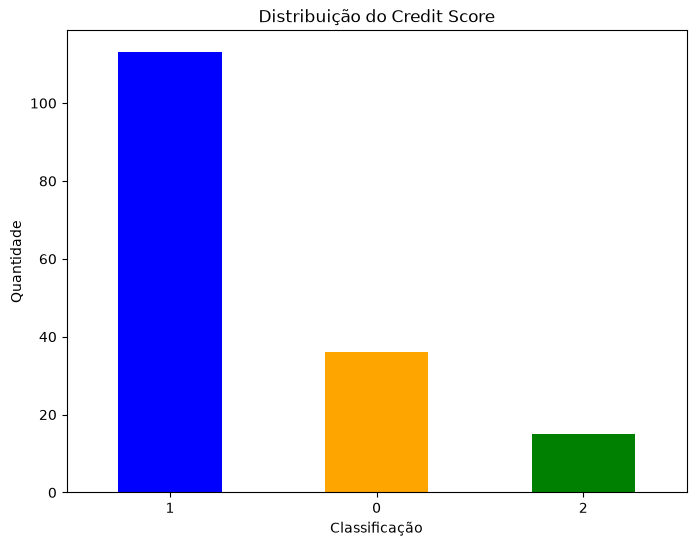

In [68]:
Credit_Score_counts = df['Credit Score'].value_counts()

plt.figure(figsize=(8, 6))
Credit_Score_counts.plot(kind='bar', color=['blue', 'orange', 'green'])

plt.title('Distribuição do Credit Score')
plt.xlabel('Classificação')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)
plt.show()

In [69]:
print((df['Credit Score'].value_counts(normalize=True) * 100))

Credit Score
1    68.902439
0    21.951220
2     9.146341
Name: proportion, dtype: float64


**H) Vamos realizar o balancecamento dos dados da coluna de credit score.**
Se lembre que realizazmos apenas para a base de treino.

In [70]:
from imblearn.over_sampling import SMOTE

# Criar uma instância do SMOTE
smote = SMOTE(random_state=42)

# Aplicar o SMOTE aos dados de treinamento (X_train, y_train)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Verificar a distribuição das classes após o balanceamento
print("Distribuição das classes após o balanceamento:")
print(y_train_balanced.value_counts())

Distribuição das classes após o balanceamento:
Credit Score
0    84
2    84
1    84
Name: count, dtype: int64
